# Project data exploration - looking at relplot and scatter plots
Using a dataset that your group is consider using for the term project, let's do some data exploring of the different features in your dataset and their relationships

Group name: Group 11
Created by Hien Nguyen (018312112), Thy Tran (ID HERE), Evie Ho (018929807), Ashton Moraes (018629832) \
Last updated: 10/24/2026 \
Dataset: https://www.kaggle.com/datasets/joebeachcapital/30000-spotify-songs \
This dataset contains information about 30,000 songs that can be found on Spotify, and has a mix of musical data as well as other relevant metadata about a track. Examples of musical data include key, loudness, acousticness, and speechiness. Examples of the other metadata include genre, release date, popularity, and artist. Through exploring this dataset, we can understand the relationship between the musical data and the popularity or other metadata that may lead to some insights.



In [9]:
# Import relevant packages and libraries
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from google.colab import drive

# Download CSV file to Google Drive root directory before accessing
drive.mount('/content/drive')
path = "/content/drive/MyDrive/spotify_songs.csv"

# Import data from CSV
spotify = pd.read_csv(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# Explore dataset
spotify.info()
spotify.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudne

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


## Q1: Data background
Provide a brief summary of the data including source, size of data, topic, and what the motivation behind exploring this dataset.

*The data is a CSV file sourced from Kaggle that contains data about 32,833 songs that are on Spotify. The file itself was around 8MB, and there are 32,833 data records. The data includes a mix of musical data as well as song metadata. Examples of the musical data are key, loudness, acousticness, and speechiness. Examples of the song metadata are song name, artist, popularity, and duration. We would like to explore this dataset in order to answer questions regarding how certain musical factors might impact the popularity of a song, or how genres or songs have changed over time.*

### Q2: Show the number of missing data in each column of the dataframe
If you have missing data, how much? which column(s)? Do you think it will impact your output?

In [11]:
spotify.isnull().sum()

,0
track_id,0
track_name,5
track_artist,5
track_popularity,0
track_album_id,0
track_album_name,5
track_album_release_date,0
playlist_name,0
playlist_id,0
playlist_genre,0


There are 5 missing values in track_name, track_artist, and track_album_name, while all the other columns have no missing values. Since the dataset has 32,833 records, this is a very small amount of missing data and should not have much impact on our analysis. We may just need to handle these missing values if we decide to use those three columns later.

### Q3: Show the data type for each column of the dataframe
Is the data type as expected? Is it clear what the content/value of each column is?

In [12]:
spotify.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudne

Most of the data types are what we expected. The columns containing names, IDs, and categories are stored as objects, while the musical features are mostly stored as integers or floats. The content of each column is also fairly clear based on the column names. One thing we noticed is that track_album_release_date is stored as an object instead of a date, so we may need to convert it later if we want to analyze how songs or music have changed over time.

### Q4: Your own question using `relplot()`
**Question:** Insert question here

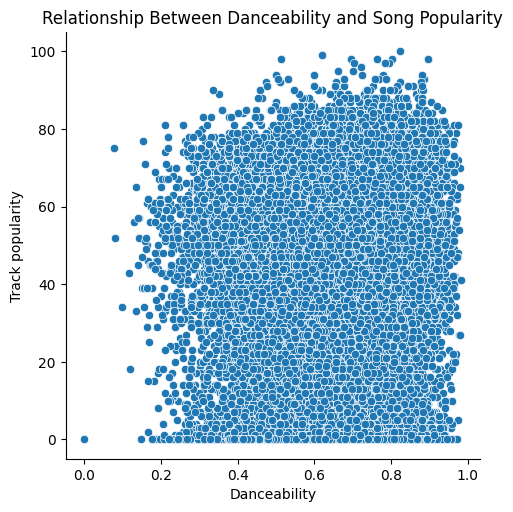

In [13]:
# Relationship between danceability and popularity
sns.relplot(
    data=spotify,
    x="danceability",
    y="track_popularity",
    kind="scatter",
    height=5
)

# Label plot
plt.xlabel("Danceability")
plt.ylabel("Track popularity")
plt.title("Relationship Between Danceability and Song Popularity")
plt.show()

### Q5: Your own question using `catplot()`
**Question:** Which genres are more popular on average?

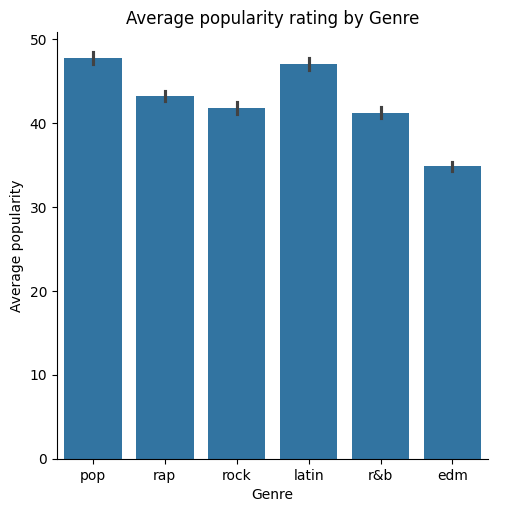

In [14]:
# Categorical plot of genres and popularity
sns.catplot(
    data = spotify,
    x = "playlist_genre",
    y = "track_popularity",
    kind = "bar",
)

# Label plot
plt.xlabel("Genre")
plt.ylabel("Average popularity")
plt.title("Average popularity rating by Genre")
plt.show()

### Q6: Create a plot with small multiples plots
Select two features from your dataset and show the relationship between the features with an additional feature as the single category. Organize the multiple plots to have 3 plots per row. Set the `height` of the plot to 5 and the size the of data point to 20. Include a meaningful title in the plot.

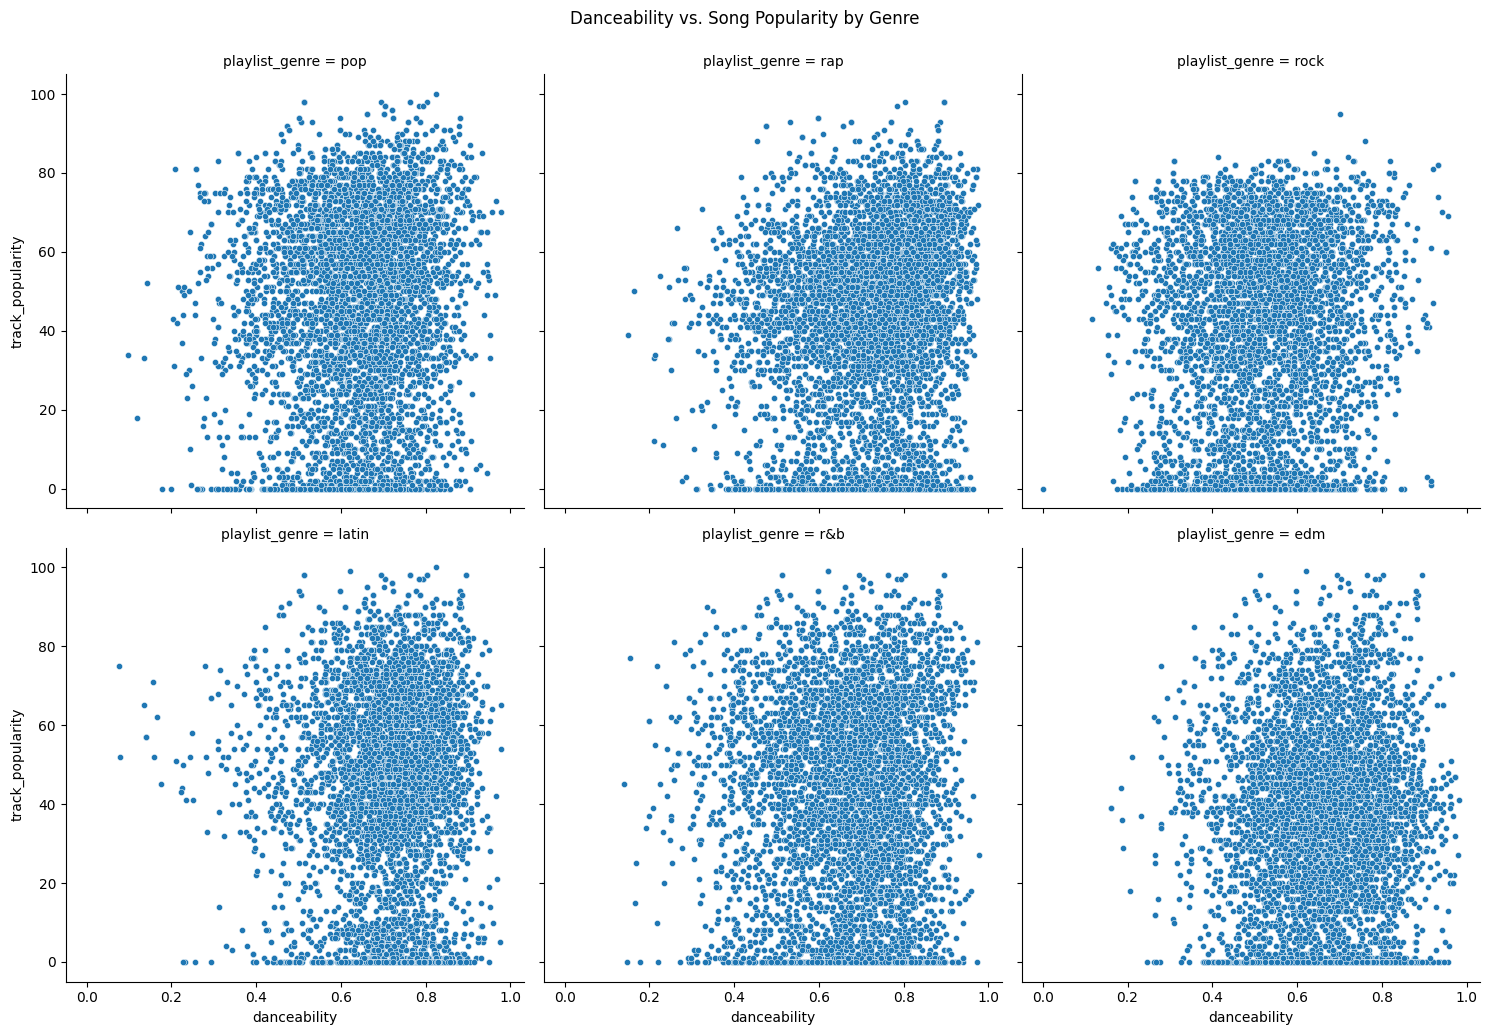

In [15]:
# Your code here . . .
# Relationship between danceability and popularity by genre
sns.relplot(
    data=spotify,
    x="danceability",
    y="track_popularity",
    col="playlist_genre",
    col_wrap=3,
    kind="scatter",
    height=5,
    s=20
)

# Add a meaningful title
plt.suptitle(
    "Danceability vs. Song Popularity by Genre",
    y=1.03
)

plt.show()